In [3]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## 4.2 Importing Data

In [7]:
df = pd.read_csv('/Users/reaganbonham/python_decal_fa26/reagan/homework7/exoplanet_data.csv', comment='#')
print(df)

         pl_name   hostname  default_flag  sy_snum  sy_pnum  discoverymethod  \
0        7 CMa c      7 CMa             0        1        2  Radial Velocity   
1        7 CMa c      7 CMa             1        1        2  Radial Velocity   
2       DMPP-1 b     DMPP-1             1        1        4  Radial Velocity   
3       DMPP-1 b     DMPP-1             0        1        4  Radial Velocity   
4       DMPP-1 c     DMPP-1             0        1        4  Radial Velocity   
..           ...        ...           ...      ...      ...              ...   
594    bet Pic c    bet Pic             0        1        3  Radial Velocity   
595  eps Ind A b  eps Ind A             0        3        1  Radial Velocity   
596  eps Ind A b  eps Ind A             1        3        1  Radial Velocity   
597  eps Ind A b  eps Ind A             0        3        1  Radial Velocity   
598  eps Ind A b  eps Ind A             0        3        1  Radial Velocity   

     disc_year           disc_facility 

In [8]:
print(df.shape)

(599, 92)


In [10]:
print(df.shape[0]) #rows
print(df.shape[1]) #columns

599
92


In [17]:
print(df.columns)
print(df.index)

Index(['pl_name', 'hostname', 'default_flag', 'sy_snum', 'sy_pnum',
       'discoverymethod', 'disc_year', 'disc_facility', 'soltype',
       'pl_controv_flag', 'pl_refname', 'pl_orbper', 'pl_orbpererr1',
       'pl_orbpererr2', 'pl_orbperlim', 'pl_orbsmax', 'pl_orbsmaxerr1',
       'pl_orbsmaxerr2', 'pl_orbsmaxlim', 'pl_rade', 'pl_radeerr1',
       'pl_radeerr2', 'pl_radelim', 'pl_radj', 'pl_radjerr1', 'pl_radjerr2',
       'pl_radjlim', 'pl_bmasse', 'pl_bmasseerr1', 'pl_bmasseerr2',
       'pl_bmasselim', 'pl_bmassj', 'pl_bmassjerr1', 'pl_bmassjerr2',
       'pl_bmassjlim', 'pl_bmassprov', 'pl_orbeccen', 'pl_orbeccenerr1',
       'pl_orbeccenerr2', 'pl_orbeccenlim', 'pl_insol', 'pl_insolerr1',
       'pl_insolerr2', 'pl_insollim', 'pl_eqt', 'pl_eqterr1', 'pl_eqterr2',
       'pl_eqtlim', 'ttv_flag', 'st_refname', 'st_spectype', 'st_teff',
       'st_tefferr1', 'st_tefferr2', 'st_tefflim', 'st_rad', 'st_raderr1',
       'st_raderr2', 'st_radlim', 'st_mass', 'st_masserr1', 'st_masserr2

#### I don't know what most of them mean tbh. Except for maybe discoverymethod, disc_year, hostname

## 4.3 Reducing Data

### 1. Planet Name
##### Database Column Name: pl_name†
##### Description of Parameter: "Planet name most commonly used in the literature"
##### Description in my own words: The most popular name of the planet.

### 2. Host Name
##### Database Column Name: hostname†
##### Description of Parameter: "Stellar name most commonly used in the literature"
##### Description in my own words: The most popular name of the star.

### 3. Discovery Method
##### Database Column Name: discoverymethod†
##### Description of Parameter: "Method by which the planet was first identified"
##### Description in my own words: This is the method they used to find exoplanets. For example, radial velocity or transit.

### 4. Spectral Type
##### Database Column Name: st_spectype
##### Description of Parameter: "Classification of the star based on their spectral characteristics following the Morgan-Keenan system"
##### Description in my own words: What type of star the planet orbits based on its size, luminosity, and temperature.

### 5. Equilibrium Temperature
##### Database Column Name: pl_eqt†
##### Description of Parameter: "The equilibrium temperature of the planet as modeled by a black body heated only by its host star, or for directly imaged planets, the effective temperature of the planet required to match the measured luminosity if the planet were a black body"
##### Description in my own words: Essentially just the temperature of the planet.

### 6. Planet Mass or Mass*sin(i)
##### Database Column Name: pl_bmasse†
##### Description of Parameter: "Best planet mass estimate available, in order of preference: Mass, M*sin(i)/sin(i), or M*sin(i), depending on availability, and measured in Earth masses"
##### Description in my own words: The mass of the exoplanet relative to Earth's mass.

In [22]:
kept_data = [
    'pl_name',
    'hostname',
    'discoverymethod',
    'st_spectype',
    'pl_eqt',
    'pl_bmasse'
]

new_data = df[kept_data]

filtered_data = new_data.dropna()

print(filtered_data)

         pl_name   hostname  discoverymethod st_spectype  pl_eqt    pl_bmasse
3       DMPP-1 b     DMPP-1  Radial Velocity        F8 V   877.0    24.270000
4       DMPP-1 c     DMPP-1  Radial Velocity        F8 V  1239.0     9.600000
6       DMPP-1 d     DMPP-1  Radial Velocity        F8 V  1632.0     3.350000
8       DMPP-1 e     DMPP-1  Radial Velocity        F8 V  1314.0     4.130000
9       DMPP-2 b     DMPP-2  Radial Velocity        F5 V  1000.0   138.891710
..           ...        ...              ...         ...     ...          ...
575   WASP-185 b   WASP-185          Transit        G0 V  1160.0   311.473400
580   WASP-190 b   WASP-190          Transit     F6 IV-V  1500.0   317.830000
582   WASP-192 b   WASP-192          Transit        G0 V  1620.0   731.009000
585       XO-7 b       XO-7          Transit        G0 V  1743.0   225.341470
597  eps Ind A b  eps Ind A  Radial Velocity        K5 V   275.0  2005.497248

[77 rows x 6 columns]


In [23]:
print(filtered_data.shape)

(77, 6)


In [25]:
print(filtered_data.shape[0]) #rows
print(filtered_data.shape[1]) #columns

77
6


In [28]:
print(filtered_data.head(5))
print(filtered_data.tail(5))

    pl_name hostname  discoverymethod st_spectype  pl_eqt  pl_bmasse
3  DMPP-1 b   DMPP-1  Radial Velocity        F8 V   877.0   24.27000
4  DMPP-1 c   DMPP-1  Radial Velocity        F8 V  1239.0    9.60000
6  DMPP-1 d   DMPP-1  Radial Velocity        F8 V  1632.0    3.35000
8  DMPP-1 e   DMPP-1  Radial Velocity        F8 V  1314.0    4.13000
9  DMPP-2 b   DMPP-2  Radial Velocity        F5 V  1000.0  138.89171
         pl_name   hostname  discoverymethod st_spectype  pl_eqt    pl_bmasse
575   WASP-185 b   WASP-185          Transit        G0 V  1160.0   311.473400
580   WASP-190 b   WASP-190          Transit     F6 IV-V  1500.0   317.830000
582   WASP-192 b   WASP-192          Transit        G0 V  1620.0   731.009000
585       XO-7 b       XO-7          Transit        G0 V  1743.0   225.341470
597  eps Ind A b  eps Ind A  Radial Velocity        K5 V   275.0  2005.497248


In [30]:
print(filtered_data.columns)

Index(['pl_name', 'hostname', 'discoverymethod', 'st_spectype', 'pl_eqt',
       'pl_bmasse'],
      dtype='str')


## 4.3 Analyze Data

In [37]:
filtered_data['discoverymethod'].value_counts()

discoverymethod
Transit            62
Radial Velocity    13
Imaging             2
Name: count, dtype: int64

##### Discovery methods are transit, radial velocity, and imaging.
##### 62 detected via transit, 13 via RV, and 2 via imaging. Transit has the most and imaging the least

##### Transit: detecting an exoplanet by seeig it pass in front of a star
##### Radia Velocity: Determining the mass of an exoplanet by measuring the Doppler Wobble of the star
##### Imaging: Detecting an exoplanet through taking pictures

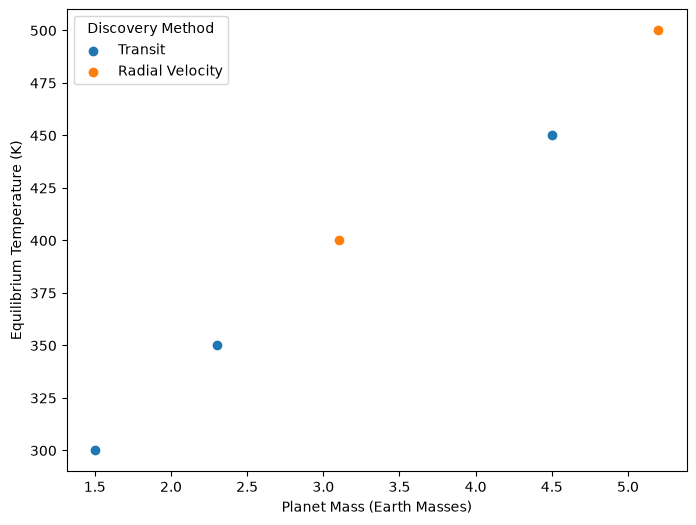

In [50]:
plt.figure(figsize = (8, 6))
data = pd.DataFrame({
    'pl_bmasse': [1.5, 2.3, 3.1, 4.5, 5.2],
    'pl_eqt': [300, 350, 400, 450, 500],
    'pl_discmethod': ['Transit', 'Transit', 'Radial Velocity', 'Transit', 'Radial Velocity']
})
methods = data['pl_discmethod'].unique()
for method in methods:
    subset = data[data['pl_discmethod'] == method]
    plt.scatter(
        subset['pl_bmasse'],
        subset['pl_eqt'],
        label = method)
plt.xlabel('Planet Mass (Earth Masses)')
plt.ylabel('Equilibrium Temperature (K)')
plt.legend(title = 'Discovery Method')
plt.show()

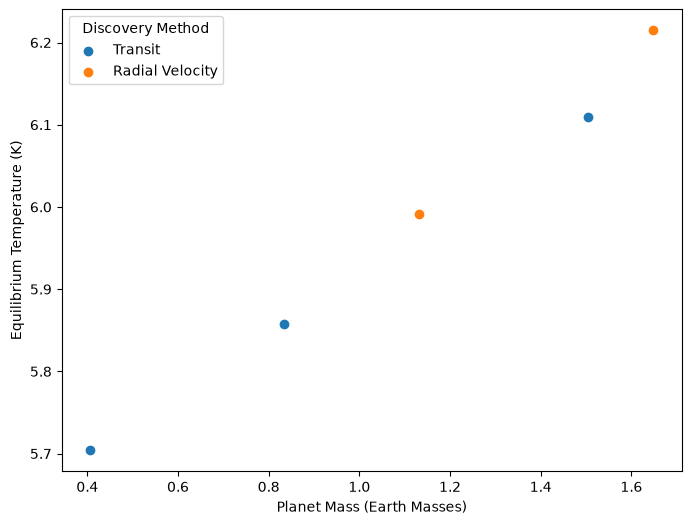

In [53]:
plt.figure(figsize = (8, 6))
data = pd.DataFrame({
    'pl_bmasse': [1.5, 2.3, 3.1, 4.5, 5.2],
    'pl_eqt': [300, 350, 400, 450, 500],
    'pl_discmethod': ['Transit', 'Transit', 'Radial Velocity', 'Transit', 'Radial Velocity']
})
methods = data['pl_discmethod'].unique()
for method in methods:
    subset = data[data['pl_discmethod'] == method]
    plt.scatter(
        np.log(subset['pl_bmasse']),
        np.log(subset['pl_eqt']),
        label = method)
plt.xlabel('Log Planet Mass (Earth Masses)')
plt.ylabel('Log Equilibrium Temperature (K)')
plt.legend(title = 'Discovery Method')
plt.show()

##### Much more likely to be massive

In [57]:
coldest_exoplanet = filtered_data[filtered_data['pl_bmasse'] > 5].sort_values(by = 'pl_eqt').iloc[0]
print(coldest_exoplanet)

pl_name                   GJ 357 d
hostname                    GJ 357
discoverymethod    Radial Velocity
st_spectype                 M2.5 V
pl_eqt                       219.6
pl_bmasse                      6.1
Name: 76, dtype: object


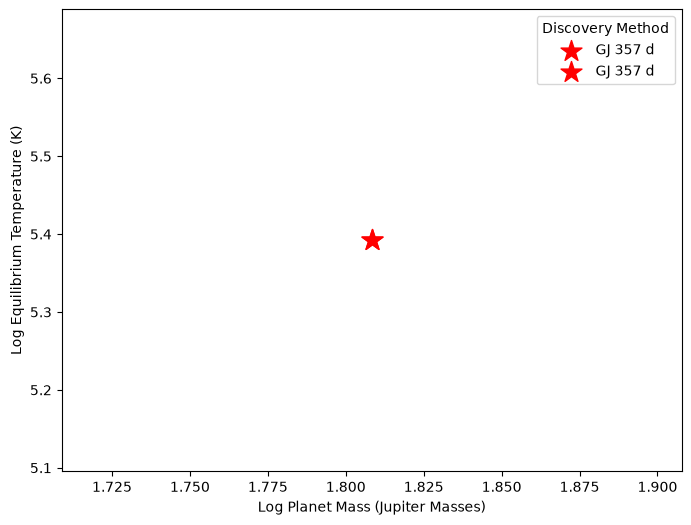

In [59]:
plt.figure(figsize = (8, 6))
data = pd.DataFrame({
    'pl_bmasse': [1.5, 2.3, 3.1, 4.5, 5.2],
    'pl_eqt': [300, 350, 400, 450, 500],
    'pl_discmethod': ['Transit', 'Transit', 'Radial Velocity', 'Transit', 'Radial Velocity']
})
methods = data['pl_discmethod'].unique()
for method in methods:
    subset = data[data['pl_discmethod'] == method]
    plt.scatter(
        np.log(coldest_exoplanet['pl_bmasse']),
        np.log(coldest_exoplanet['pl_eqt']),
        color = 'red',
        marker = '*',
        s = 250,
        label = coldest_exoplanet['pl_name'])
plt.xlabel('Log Planet Mass (Jupiter Masses)')
plt.ylabel('Log Equilibrium Temperature (K)')
plt.legend(title = 'Discovery Method')
plt.show()

#### Title: "A temperate super-Jupiter imaged with JWST in the mid-infrared"
#### Summary: JWST was used to take the first images of exoplanets that are older and cooler, since before that, the only detected exoplanets were extremely hot